# n→∞ ID / OOD test-error floors vs **task diversity**, with dMMSE / Ridge oracles

Companion to `run_eigenlearning_fixed_tasks_multi_d_testing_OOD.ipynb` (which plots ID/OOD error
**vs n**). Here we plot, **vs task diversity `T`** (log₂-spaced, 1…4096): the **kernel floor** — the
n→∞ KRR risk from `ood_inputs` — against the two in-context Bayes **oracles** from
`kernels_can_icl/oracle_models.py`: **dMMSE** (posterior mean over the `T` discrete pretraining tasks) and
**Ridge** (posterior mean under the continuous `N(0, I)` prior).

**One shared draw of `betas` per sample** (from `make_tasks`) feeds *both* the floor
(`ood_inputs(betas, …)`) and the oracles (dMMSE's candidate set is that same `betas`; the ID query
task is a row of `betas`, the OOD query task is a fresh isotropic Gaussian). The pretraining task
shape is `KIND_TRAIN` (default `"normal"`); **the OOD test prior always stays isotropic `N(0, I)`**.

**Task moments are PER-ROW empirical** (`ood_inputs(..., pooled=False)`): the degree-1 eigcoeffs equal
the actual task mean `Mb[k]=E_tasks[β_k]`. At `T=1` that *is* the single task, so the kernel learns
exactly that one task vector — the **ID floor collapses to the noise floor `e/norm2`** and the kernel
floor **coincides with dMMSE**. (Pooling all `T·d` coords — `pooled=True` — is faster but wrong at
small `T`; kept only as an option.) `ood_floors_fast` caches the beta-independent polynomial layer,
computes the empirical moments vectorized, and assembles each Gram with `np.bincount`; it's asserted
equal to `ood_inputs(..., pooled=False)`, fast enough for deg-7. Everything is normalized by
`norm2 = v·d + e`, so all curves share one axis.

**Four experiments:** (1) the deg-7 kernel vs the two oracles; (2) the kernel floor at every degree
cutoff `{1,3,5,7}` overlaid with the oracles; (3) a single-run (one `betas` per `T`, no averaging);
(4) same as (1) but with the pretraining `betas` drawn `kind="ondiags"`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import dataclasses
import pickle
import os

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import sys, os

GIT_USER  = "JoeyTurn"
GIT_REPO  = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

Cloning into 'kernel_ICL'...
remote: Enumerating objects: 726, done.
remote: Counting objects: 100% (261/261), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 726 (delta 179), reused 164 (delta 85), pack-reused 465 (from 1)
Receiving objects: 100% (726/726), 43.46 MiB | 17.03 MiB/s, done.
Resolving deltas: 100% (373/373), done.
Cloning into 'modelscape'...
remote: Enumerating objects: 234, done.
remote: Counting objects: 100% (234/234), done.
remote: Compressing objects: 100% (156/156), done.
remote: Total 234 (delta 142), reused 168 (delta 76), pack-reused 0 (from 0)
Receiving objects: 100% (234/234), 218.78 KiB | 21.88 MiB/s, done.
Resolving deltas: 100% (142/142), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 16.11 MiB/s, d

In [ ]:
from misc import rcsetup
rcsetup()

In [ ]:
import numpy as np, math, re, itertools, time, os, pickle
import torch
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
# --- problem params (mirror run_eigenlearning_fixed_tasks_multi_d_testing_OOD.ipynb) ---
dim        = 5
L_cfg      = 8                       # config["L"] (context length incl. query -> L_cfg-1 in-context ex.)
L          = L_cfg - 1               # falling-factorial L passed to ood_inputs (= # context tokens)
sigma_sq   = 0.1                     # e = label-noise variance
sigma_beta2 = 1.0                    # make_tasks 'normal' draws ~ N(0, I): unit per-coord variance
sigma_beta = sigma_beta2 ** 0.5
v          = 1.0/(dim*(L_cfg-1))     # sigma_x2 = 1/(d*(L-1))
norm2      = v*dim*sigma_beta2 + sigma_sq

# --- task distribution + sweep knobs ---
DEVICE     = torch.device("cpu")
KIND_TRAIN = "normal"                # in-distribution task shape (make_tasks); OOD stays N(0, I).
                                     # try: shifted, antipodal, ondiags, offdiags, isogauss, skewnormal, ...
CUTOFFS         = [1, 3, 5, 7]       # kernel degree cutoffs
T_list          = [2**k for k in range(13)]   # 1, 2, 4, ..., 4096
n_beta_samples  = 6                  # random draws of the T betas for the averaged runs
n_mc            = 1000               # Monte-Carlo contexts per sample for the oracles
seed            = 0
print(f"dim={dim}  L(falling)={L}  v=1/{round(1/v)}={v:.5f}  e={sigma_sq}  norm2={norm2:.5f}")
print("KIND_TRAIN:", KIND_TRAIN, " cutoffs:", CUTOFFS, " T_list:", T_list)

dim=5  L(falling)=7  v=1/35=0.02857  e=0.1  norm2=0.24286
KIND_TRAIN: normal  cutoffs: [1, 3, 5, 7]  T_list: [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096]


## n→∞ OOD-floor engine (pasted verbatim)

Algebra layer + `ood_features_highdeg` + `ood_inputs` (per-row empirical task moments by default; `pooled=True` for the iid-coordinate approximation) + the cached fast path (`ood_floors_fast`).

In [ ]:
# ==== Algebra helpers (from the OOD notebook, cell 9) =======================
import numpy as np, math, itertools

def _df(n):
    r = 1.0
    while n > 0: r *= n; n -= 2
    return r
def _gm(p, sb2):                                   # E[Z^p], Z ~ N(0, sb2)
    return 0.0 if p % 2 else _df(p - 1) * sb2 ** (p // 2)

def _tok_poly(px, py, v, e, d):
    def momX(p): return 0.0 if p % 2 else _df(p - 1) * v ** (p // 2)
    def comps(m, dd):
        if dd == 1: yield (m,); return
        for i in range(m + 1):
            for rest in comps(m - i, dd - 1): yield (i,) + rest
    poly = {}
    for j in range(py + 1):
        Exi = 0.0 if j % 2 else _df(j - 1) * e ** (j // 2)
        if Exi == 0.0: continue
        cj = math.comb(py, j); m = py - j
        for k in comps(m, d):
            mult = math.factorial(m)
            for kc in k: mult //= math.factorial(kc)
            xm = 1.0
            for a in range(d):
                xm *= momX(px[a] + k[a])
                if xm == 0.0: break
            if xm == 0.0: continue
            poly[k] = poly.get(k, 0.0) + cj * Exi * mult * xm
    return poly

def _padd(p1, p2, s=1.0):
    out = dict(p1)
    for k, c in p2.items(): out[k] = out.get(k, 0.0) + s * c
    return out
def _pmul(p1, p2):
    out = {}
    for k1, c1 in p1.items():
        for k2, c2 in p2.items():
            k = tuple(a + b for a, b in zip(k1, k2))
            out[k] = out.get(k, 0.0) + c1 * c2
    return out
def _gaussmean(p, sb2):
    s = 0.0
    for k, c in p.items():
        t = c
        for kc in k:
            t *= _gm(kc, sb2)
            if t == 0.0: break
        s += t
    return s
def _empmean(p, betas):
    s = np.zeros(betas.shape[0])
    for k, c in p.items():
        t = c * np.ones(betas.shape[0])
        for ci, kc in enumerate(k):
            if kc: t = t * betas[:, ci] ** kc
        s = s + t
    return float(np.mean(s))

def _combine(l1, l2, d):
    return [(tuple(px1[t] + px2[t] for t in range(d)), py1 + py2, c1 * c2)
            for px1, py1, c1 in l1 for px2, py2, c2 in l2]
def _legpoly(leg, v, e, d):
    out = {}
    for px, py, c in leg:
        for k, val in _tok_poly(px, py, v, e, d).items():
            out[k] = out.get(k, 0.0) + c * val
    return out
def _falling(L, k):
    r = 1.0
    for t in range(k): r *= (L - t)
    return r
def _prod_distinct_poly(legsA, legsB, v, e, L, d):
    p, q = len(legsA), len(legsB); total = {}
    for r in range(min(p, q) + 1):
        for S in itertools.combinations(range(q), r):
            for At in itertools.permutations(range(p), r):
                inj = {S[i]: At[i] for i in range(r)}; usedA = set(inj.values()); tokens = []
                for a in range(p):
                    if a in usedA:
                        s = next(ss for ss in S if inj[ss] == a)
                        tokens.append(_combine(legsA[a], legsB[s], d))
                    else: tokens.append(legsA[a])
                for b in range(q):
                    if b not in S: tokens.append(legsB[b])
                acc = {(0,) * d: _falling(L, len(tokens))}
                for lg in tokens: acc = _pmul(acc, _legpoly(lg, v, e, d))
                total = _padd(total, acc)
    return total

In [ ]:
# ==== ood_features_highdeg.py (user-supplied, verbatim) =====================
import re

def _xmono(d, axes, py):
    px = [0] * d
    for a in axes:
        px[a] += 1
    return (tuple(px), py, 1.0)

def build_features(d, max_degree=7):
    F = []
    tok = lambda coords, ypow: [_xmono(d, coords, ypow)]
    add = lambda legs, b, label: F.append(dict(terms=[(tuple(legs), 1.0)], b=b, label=label))
    for b in range(d):
        add([], b, f"q{b}")
        if max_degree >= 3:
            add([tok([], 2)], b, f"y2q{b}")
            for a in range(d):
                add([tok([a], 1)], b, f"X{a}yq{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a, c], 0)], b, f"X{a}X{c}q{b}")
        if max_degree >= 5:
            add([tok([], 4)], b, f"y4q{b}")
            for a in range(d):
                add([tok([a], 3)], b, f"y3X{a}q{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a, c], 2)], b, f"y2X{a}X{c}q{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a], 1), tok([c], 1)], b, f"yX{a}_yX{c}q{b}_cross")
            for a in range(d):
                add([tok([a, a], 0), tok([a], 1)], b, f"yXdotX{a}q{b}_cross")
        if max_degree >= 7:
            add([tok([], 6)], b, f"y6q{b}")
            for a in range(d):
                add([tok([a], 5)], b, f"y5X{a}q{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a, c], 4)], b, f"y4X{a}X{c}q{b}")
            for a in range(d):
                for c in range(a, d):
                    for e in range(c, d):
                        add([tok([a, c, e], 3)], b, f"y3X{a}X{c}X{e}q{b}")
            for a in range(d):
                for c in range(d):
                    add([tok([a], 3), tok([c], 1)], b, f"y3X{a}_yX{c}q{b}_cross")
    return F

_FEAT_PATS = [
    (r'y3X(\d+)_yX(\d+)q(\d+)_cross', 'y3X_yX'),
    (r'yX(\d+)_yX(\d+)q(\d+)_cross',  'yX_yX'),
    (r'yXdotX(\d+)q(\d+)_cross',      'yXdotX'),
    (r'y6q(\d+)',                     'y6'),
    (r'y5X(\d+)q(\d+)',               'y5X'),
    (r'y4X(\d+)X(\d+)q(\d+)',         'y4XX'),
    (r'y4q(\d+)',                     'y4'),
    (r'y3X(\d+)X(\d+)X(\d+)q(\d+)',   'y3XXX'),
    (r'y3X(\d+)q(\d+)',               'y3X'),
    (r'y2X(\d+)X(\d+)q(\d+)',         'y2XX'),
    (r'y2q(\d+)',                     'y2'),
    (r'X(\d+)yq(\d+)',                'Xy'),
    (r'X(\d+)X(\d+)q(\d+)',           'XX'),
    (r'q(\d+)',                       'q'),
]
_FEAT_DEG = {'q': 1, 'Xy': 3, 'XX': 3, 'y2': 3,
             'y4': 5, 'y3X': 5, 'y2XX': 5, 'yX_yX': 5, 'yXdotX': 5,
             'y6': 7, 'y5X': 7, 'y4XX': 7, 'y3XXX': 7, 'y3X_yX': 7}

def _feat_coords(label):
    for pat, kind in _FEAT_PATS:
        m = re.fullmatch(pat, label)
        if m:
            g = list(map(int, m.groups()))
            return kind, tuple(g[:-1]), g[-1]
    raise ValueError(f"unrecognized feature label {label!r}; extend _FEAT_PATS")

def _feat_degree(label):
    return _FEAT_DEG[_feat_coords(label)[0]]

def _canon_label(label):
    kind, inp, b = _feat_coords(label)
    sw = lambda c: 0 if c == b else (b if c == 0 else c)
    i0 = tuple(sorted(sw(c) for c in inp))
    if kind == 'q':  return 'q0'
    if kind == 'y2': return 'y2q0'
    if kind == 'Xy': return f'X{i0[0]}yq0'
    if kind == 'XX': return f'X{i0[0]}X{i0[1]}q0'
    raise ValueError(f"_canon_label only supports degree<=3; got {label!r}")

In [ ]:
# ==== New pooled engine (user-supplied, verbatim) ===========================
def _poolmean(p, mom):
    s = 0.0
    for k, c in p.items():
        t = c
        for kc in k:
            t *= mom[kc]
        s += t
    return s

def _gram2(Fsel, v, e, L, d, red_p, red_q):
    P = len(Fsel); Gp = np.zeros((P, P)); Gq = np.zeros((P, P))
    for i in range(P):
        for j in range(i, P):
            if Fsel[i]['b'] != Fsel[j]['b']:
                continue
            poly = {}
            for li, ci in Fsel[i]['terms']:
                for lj, cj in Fsel[j]['terms']:
                    poly = _padd(poly, _prod_distinct_poly(li, lj, v, e, L, d), ci * cj)
            gp = v * red_p(poly); gq = v * red_q(poly)
            Gp[i, j] = Gp[j, i] = gp; Gq[i, j] = Gq[j, i] = gq
    return Gp, Gq

def _Vvec2(Fsel, v, e, L, d, red_p, red_q):
    Vp = np.zeros(len(Fsel)); Vq = np.zeros(len(Fsel))
    for i, F in enumerate(Fsel):
        b = F['b']; poly = {}
        for legs, c in F['terms']:
            poly = _padd(poly, _prod_distinct_poly(legs, (), v, e, L, d), c)
        poly_b = {tuple(k[t] + (1 if t == b else 0) for t in range(d)): cc for k, cc in poly.items()}
        Vp[i] = v * red_p(poly_b); Vq[i] = v * red_q(poly_b)
    return Vp, Vq

def ood_inputs(betas_train, test_prior, v, e, L, d, marked, tol=1e-10, kmax=12,
               exact=False, max_degree=7, pooled=False):
    # pooled=False (default): PER-ROW empirical task moments, so the degree-1 eigcoeffs equal the
    # actual task mean Mb[k]=E_tasks[beta_k] (= the single task itself at T=1). pooled=True uses the
    # iid-coordinate pooled marginal (fast/axis-symmetric) but is WRONG at small T (it can't represent
    # a specific task vector). See notebook markdown.
    betas_train = np.asarray(betas_train, float)
    mom = np.array([np.mean(betas_train.ravel() ** k) for k in range(kmax + 1)])
    p_red = (lambda p: _poolmean(p, mom)) if pooled else (lambda p: _empmean(p, betas_train))
    signal_p = (d * mom[2] * v) if pooled else float(np.mean(np.sum(betas_train ** 2, 1))) * v

    kind, payload = test_prior
    if kind == 'gauss':
        sb2 = float(payload); q_red = lambda p: _gaussmean(p, sb2); Eb2 = sb2
    else:
        bt = np.asarray(payload, float)
        if pooled:
            momq = np.array([np.mean(bt.ravel() ** k) for k in range(kmax + 1)])
            q_red = lambda p: _poolmean(p, momq); Eb2 = float(momq[2])
        else:
            q_red = lambda p: _empmean(p, bt); Eb2 = float(np.mean(np.sum(bt ** 2, 1)) / d)

    F = build_features(d, max_degree)
    lab2 = {f['label']: i for i, f in enumerate(F)}
    for b in range(d):
        lab2.setdefault(f"Xyq{b}",  lab2.get(f"X{b}yq{b}"))
        lab2.setdefault(f"X2q{b}",  lab2.get(f"X{b}X{b}q{b}"))
        lab2.setdefault(f"y3Xq{b}", lab2.get(f"y3X{b}q{b}"))
        lab2.setdefault(f"y5Xq{b}", lab2.get(f"y5X{b}q{b}"))
    by_axis = {}
    for i, f in enumerate(F):
        by_axis.setdefault(f['b'], []).append(i)

    real = [(p, F[lab2[m]]['b'], F[lab2[m]]['label'])
            for p, m in enumerate(marked) if lab2.get(m) is not None]

    def _diag_deg3(li):
        _, inp, bb = _feat_coords(li)
        return _feat_degree(li) <= 3 and all(c == bb for c in inp)
    fast = pooled and (not exact) and all(_diag_deg3(li) for _, _, li in real)

    Pm = len(marked)
    v_tr = np.zeros(Pm); v_te = np.zeros(Pm); a = np.zeros(Pm); S = np.eye(Pm)

    def _block(idxs):
        Fb = [F[i] for i in idxs]
        Gp, Gq = _gram2(Fb, v, e, L, d, p_red, q_red)
        Vp, Vq = _Vvec2(Fb, v, e, L, d, p_red, q_red)
        Lc = np.linalg.cholesky(Gp + tol * np.mean(np.diag(Gp)) * np.eye(len(idxs)))
        Li = np.linalg.solve(Lc, np.eye(len(idxs)))
        Sb = Li @ Gq @ Li.T; vtr = Li @ Vp; ab = Li @ Vq
        return Sb, vtr, ab, np.linalg.solve(Sb, ab), {F[i]['label']: t for t, i in enumerate(idxs)}

    if fast:
        Sb, vtr, ab, vte, pos = _block(by_axis[0])
        by_b = {}
        for p, b, li in real:
            by_b.setdefault(b, []).append((p, li))
        for members in by_b.values():
            for p, li in members:
                t = pos[_canon_label(li)]
                v_tr[p] = vtr[t]; a[p] = ab[t]; v_te[p] = vte[t]
                for pj, lj in members:
                    S[p, pj] = Sb[t, pos[_canon_label(lj)]]
    else:
        for b in sorted({bb for _, bb, _ in real}):
            Sb, vtr, ab, vte, pos = _block(by_axis[b])
            for pi, bi, li in real:
                if bi != b:
                    continue
                v_tr[pi] = vtr[pos[li]]; a[pi] = ab[pos[li]]; v_te[pi] = vte[pos[li]]
                for pj, bj, lj in real:
                    if bj == b:
                        S[pi, pj] = Sb[pos[li], pos[lj]]

    signal_q = Eb2 * d * v
    residual = max(signal_q - float(a @ v_te), 0.0)
    norm2 = signal_q + e
    delta = v_te - v_tr
    resid_p = max(signal_p - float(v_tr @ v_tr), 0.0)
    s = np.sqrt(norm2)
    return dict(eigcoeffs_train=v_tr / s,
                eigcoeffs_test=v_te / s,
                test_gram_OOD=S,
                noise_var_eff=(residual + e) / norm2,
                noise_var_train_eff=(resid_p + e) / norm2,
                floor=float(delta @ S @ delta + residual + e) / norm2)

In [ ]:
# ---- canonical context key (for the axis-symmetry permutation) -------------
def _ctx_key(f, swap):
    toks = []
    for leg in f['terms'][0][0]:
        for (px, py, _c) in leg:
            toks.append((tuple(px[swap[i]] for i in range(len(px))), py))
    return tuple(sorted(toks))

def _flatten(polys_ix_cs, nrows):
    """polys_ix_cs: list of (coeffs, kidx) -> flat (seg, kidx, coef) for np.bincount assembly."""
    seg, kidx, coef = [], [], []
    for r, (cs, ix) in enumerate(polys_ix_cs):
        seg.append(np.full(len(cs), r, dtype=np.intp)); kidx.append(ix); coef.append(cs)
    z = (np.zeros(0, np.intp), np.zeros(0, np.intp), np.zeros(0))
    return (np.concatenate(seg) if seg else z[0],
            np.concatenate(kidx) if kidx else z[1],
            np.concatenate(coef) if coef else z[2], nrows)

# ---- precompute: reference-block polynomial layer -> distinct multi-indices Kmat + flat
#      (segment, kidx, coeff) arrays so per-sample assembly is a vectorized np.bincount.
def precompute_ood(v, e, L, d, marked, max_degree=7, tol=1e-10, axis_symmetric=True):
    F = build_features(d, max_degree)
    lab2 = {f['label']: i for i, f in enumerate(F)}
    for b in range(d):
        lab2.setdefault(f"Xyq{b}",  lab2.get(f"X{b}yq{b}"))
        lab2.setdefault(f"X2q{b}",  lab2.get(f"X{b}X{b}q{b}"))
        lab2.setdefault(f"y3Xq{b}", lab2.get(f"y3X{b}q{b}"))
        lab2.setdefault(f"y5Xq{b}", lab2.get(f"y5X{b}q{b}"))
    by_axis = {}
    for i, f in enumerate(F):
        by_axis.setdefault(f['b'], []).append(i)
    real = [(p, F[lab2[m]]['b'], F[lab2[m]]['label'])
            for p, m in enumerate(marked) if lab2.get(m) is not None]
    axes = sorted({bb for _, bb, _ in real})
    b0 = axes[0] if axes else 0

    F0 = [F[i] for i in by_axis[b0]]; P = len(F0)
    Kset = {}
    def _reg(poly):
        cs = np.empty(len(poly)); ix = np.empty(len(poly), dtype=np.intp)
        for t, (k, c) in enumerate(poly.items()):
            ix[t] = Kset.setdefault(k, len(Kset)); cs[t] = c
        return cs, ix
    iu, ju = np.triu_indices(P)
    gram_pairs = []
    for i, j in zip(iu, ju):
        poly = {}
        for li, ci in F0[i]['terms']:
            for lj, cj in F0[j]['terms']:
                poly = _padd(poly, _prod_distinct_poly(li, lj, v, e, L, d), ci * cj)
        gram_pairs.append(_reg(poly))
    vpoly = []
    for f in F0:
        bb = f['b']; poly = {}
        for legs, c in f['terms']:
            poly = _padd(poly, _prod_distinct_poly(legs, (), v, e, L, d), c)
        vpoly.append(_reg({tuple(k[t] + (1 if t == bb else 0) for t in range(d)): cc
                           for k, cc in poly.items()}))
    Kmat = np.array(list(Kset.keys()), dtype=np.intp) if Kset else np.zeros((0, d), np.intp)
    key0 = {_ctx_key(F0[t], list(range(d))): t for t in range(P)}
    block0 = dict(P=P, Kmat=Kmat, iu=iu, ju=ju,
                  gram=_flatten(gram_pairs, len(iu)), vvec=_flatten(vpoly, P),
                  pos={F0[t]['label']: t for t in range(P)})

    blocks = {b0: block0}; perm = {b0: np.arange(P)}
    for b in axes:
        if b == b0:
            continue
        Fb = [F[i] for i in by_axis[b]]
        blocks[b] = dict(P=len(Fb), pos={Fb[t]['label']: t for t in range(len(Fb))})
        swap = list(range(d)); swap[b0], swap[b] = b, b0
        perm[b] = np.array([key0[_ctx_key(Fb[t], swap)] for t in range(len(Fb))])
    return dict(real=real, axes=axes, b0=b0, blocks=blocks, perm=perm,
                axis_symmetric=True, Pm=len(marked), d=d, v=v, e=e, tol=tol)

def _gauss_moments(Kmat, sb2):
    if Kmat.size == 0:
        return np.ones(0)
    gmtab = np.array([_gm(p, sb2) for p in range(int(Kmat.max()) + 1)])
    M = np.ones(Kmat.shape[0])
    for c in range(Kmat.shape[1]):
        M *= gmtab[Kmat[:, c]]
    return M

def _assemble(block, M, v):
    seg, kidx, coef, nP = block['gram']
    gu = np.bincount(seg, weights=coef * M[kidx], minlength=nP) * v
    P = block['P']; G = np.zeros((P, P)); iu, ju = block['iu'], block['ju']
    G[iu, ju] = gu; G[ju, iu] = gu
    vseg, vkidx, vcoef, nV = block['vvec']
    V = np.bincount(vseg, weights=vcoef * M[vkidx], minlength=nV) * v
    return G, V

def ood_floors_fast(pre, betas, sb2):
    """PER-ROW empirical floor. Train reduce = empirical mean over the T task rows (degree-1 eigcoeffs
    = task mean = the single task at T=1). Beta powers are gathered once; each Gram is assembled by a
    vectorized bincount. The isotropic gauss test Gram is reduced once on the reference block; axis b's
    train Gram is that block with betas' columns swapped 0<->b, mapped back by the precomputed perm.
    Matches ood_inputs(..., pooled=False)."""
    betas = np.asarray(betas, float); T = betas.shape[0]
    d, v, e, tol, Pm = pre['d'], pre['v'], pre['e'], pre['tol'], pre['Pm']
    v_tr = np.zeros(Pm); v_te = np.zeros(Pm); a = np.zeros(Pm); S = np.eye(Pm)
    b0 = pre['b0']; blk0 = pre['blocks'][b0]; Kmat = blk0['Kmat']
    maxp = int(Kmat.max()) + 1 if Kmat.size else 1
    bp = betas[:, :, None] ** np.arange(maxp)[None, None, :]                # (T,d,maxp) exponentiate once
    Gq, Vq = _assemble(blk0, _gauss_moments(Kmat, sb2), v)                 # isotropic -> once
    solves = {}
    for b in pre['axes']:
        swap = list(range(d)); swap[b0], swap[b] = b, b0
        acc = np.ones((T, Kmat.shape[0]))
        for c in range(d):
            acc *= bp[:, swap[c], Kmat[:, c]]                              # gather, no re-exponentiation
        Gp, Vp = _assemble(blk0, acc.mean(0), v)
        Lc = np.linalg.cholesky(Gp + tol * np.mean(np.diag(Gp)) * np.eye(blk0['P']))
        Li = np.linalg.solve(Lc, np.eye(blk0['P']))
        Sb = Li @ Gq @ Li.T; vtr = Li @ Vp; ab = Li @ Vq
        solves[b] = (Sb, vtr, ab, np.linalg.solve(Sb, ab))
    for pi, bi, li in pre['real']:
        Sb, vtr, ab, vte = solves[bi]
        ti = pre['perm'][bi][pre['blocks'][bi]['pos'][li]]
        v_tr[pi] = vtr[ti]; a[pi] = ab[ti]; v_te[pi] = vte[ti]
        for pj, bj, lj in pre['real']:
            if bj == bi:
                tj = pre['perm'][bi][pre['blocks'][bi]['pos'][lj]]
                S[pi, pj] = Sb[ti, tj]

    signal_q = sb2 * d * v
    residual = max(signal_q - float(a @ v_te), 0.0)
    norm2 = signal_q + e
    delta = v_te - v_tr
    signal_p = float(np.mean(np.sum(betas ** 2, 1))) * v
    resid_p = max(signal_p - float(v_tr @ v_tr), 0.0)
    return (resid_p + e) / norm2, float(delta @ S @ delta + residual + e) / norm2

## Task distribution — `make_tasks`

Generates the `T` pretraining tasks (`betas`). `KIND_TRAIN` selects the in-distribution shape; the OOD test prior is always isotropic `N(0, I)`. Non-`normal` kinds may need `T>d` or even `T` and will be skipped (NaN) at `T` where they can't be built.

In [ ]:
def make_tasks(T, d, kind, device):
    if kind == "shifted":
        # ~ N(mean, I): nonzero first moment (||mean||=r), cov=I, zero skew.
        r = 2
        u = torch.randn(d, device=device); u = u / u.norm()
        return torch.randn(T, d, device=device) + r * u

    if kind == "antipodal":
        assert T % 2 == 0, "antipodal needs even T"
        h = torch.randn(T // 2, d, device=device)
        return torch.cat([h, -h], dim=0)[torch.randperm(T, device=device)]

    if kind == "ondiags":
        h = torch.randn(T, d, device=device)
        h = h - h.mean(0, keepdim=True)            # beta_bar = 0 exactly
        C = (h.T @ h) / T
        _, U = torch.linalg.eigh(C)
        return h @ U                               # decorrelated: cov = diag(evals)

    if kind == "offdiags":
        # anisotropic prior rotated OFF the coordinate axes -> sizeable off-diagonal cov. beta_bar=0.
        aniso = 8.0
        h = torch.randn(T, d, device=device)
        h = h - h.mean(0, keepdim=True)
        evals, U = torch.linalg.eigh((h.T @ h) / T)
        Zw = (h @ U) / evals.clamp_min(1e-12).sqrt()   # whiten: cov = I
        s = torch.linspace(1.0, aniso, d, device=device)
        s = s / s.pow(2).mean().sqrt()
        Q, R = torch.linalg.qr(torch.randn(d, d, device=device))
        Q = Q * torch.sign(torch.diagonal(R))          # Haar rotation
        return (Zw * s) @ Q

    elif kind == "isogauss":
        # cov=I exactly, higher moments isotropic AND small (excess kurtosis/6th -> 0).
        if T <= d:
            raise ValueError("isogauss needs T > d for full-rank whitening.")
        def whiten(x):
            xc = x - x.mean(0, keepdim=True)
            C = (xc.T @ xc) / T
            evals, U = torch.linalg.eigh(C)
            return xc @ (U * evals.clamp_min(1e-12).rsqrt()) @ U.T
        n_dir = min(4096, max(256, 6 * d * d))
        Gdir  = torch.randn(n_dir, d, device=device)
        U_dir = torch.cat([torch.eye(d, device=device),
                           Gdir / Gdir.norm(dim=1, keepdim=True)], 0)
        W_ISO, W_SMALL = 10.0, 1.0
        w4, w6 = 1.0, 1.0
        w = torch.randn(T, d, device=device, requires_grad=True)
        optimizer = torch.optim.LBFGS([w], max_iter=250, line_search_fn="strong_wolfe")
        def closure():
            optimizer.zero_grad()
            z  = whiten(w)
            p  = z @ U_dir.T
            m4 = (p ** 4).mean(0)
            m6 = (p ** 6).mean(0)
            iso   = w4 * (m4 / 3.0).var(unbiased=False) + w6 * (m6 / 15.0).var(unbiased=False)
            small = w4 * ((m4.mean() - 3.0) / 3.0) ** 2 + w6 * ((m6.mean() - 15.0) / 15.0) ** 2
            loss = W_ISO * iso + W_SMALL * small
            loss.backward()
            return loss
        optimizer.step(closure)
        with torch.no_grad():
            return whiten(w)

    elif kind == "skewnormal":
        # i.i.d. N(0,I) draws, ACCEPTED with prob Phi(alpha<x,u>) -> multivariate skew-normal.
        alpha  = 6.0
        do_whiten = True
        u = torch.randn(d, device=device); u = u / u.norm()
        kept, need = [], T
        while need > 0:
            g   = torch.randn(max(3 * need, 1024), d, device=device)
            acc = torch.rand(g.shape[0], device=device) < torch.special.ndtr(alpha * (g @ u))
            kept.append(g[acc]); need = T - sum(k.shape[0] for k in kept)
        h = torch.cat(kept, 0)[:T]
        h = h                                          # (beta_bar = 0 NOT subtracted; see original)
        if do_whiten:
            C = (h.T @ h) / T
            evals, U = torch.linalg.eigh(C)
            h = h @ (U * evals.clamp_min(1e-12).rsqrt()) @ U.T
        return h

    elif kind in ("unlucky_wide", "unlucky_clustered"):
        pool_mult = 64 if kind == "unlucky_wide" else 320
        M = pool_mult * T
        pool = torch.randn(M, d, device=device)
        if kind == "unlucky_wide":
            d2  = ((pool - pool.mean(0, keepdim=True)) ** 2).sum(-1)
            idx = torch.argsort(d2)[-T:]
        else:
            ctr = pool[torch.randint(M, (1,)).item()]
            d2  = ((pool - ctr) ** 2).sum(-1)
            idx = torch.argsort(d2)[:T]
        return pool[idx]

    return torch.randn(T, d, device=device)          # "normal": isotropic N(0, I)

def draw_betas(T, kind=None):
    """T pretraining tasks as an (T, dim) numpy array (floor train reduce + dMMSE candidates + ID tasks)."""
    return make_tasks(T, dim, KIND_TRAIN if kind is None else kind, DEVICE).detach().cpu().numpy().astype(float)

In [ ]:
marked_by_deg = {deg: [f['label'] for f in build_features(dim, deg)] for deg in CUTOFFS}
pre_by_deg    = {deg: precompute_ood(v, sigma_sq, L, dim, marked_by_deg[deg], deg) for deg in CUTOFFS}
for deg in CUTOFFS:
    print(f"deg<= {deg}:  # marked features = {len(marked_by_deg[deg])}")

# --- sanity: fast path == ood_inputs(pooled=False) (uses 'normal' betas, independent of KIND_TRAIN) ---
_b = draw_betas(64, kind="normal")
for deg in CUTOFFS:
    _res  = ood_inputs(_b, ('gauss', sigma_beta2), v, sigma_sq, L, dim, marked_by_deg[deg], max_degree=deg, pooled=False)
    _fast = ood_floors_fast(pre_by_deg[deg], _b, sigma_beta2)
    assert np.allclose((_res['noise_var_train_eff'], _res['floor']), _fast), f"fast != ood_inputs @deg{deg}"
print("fast path matches ood_inputs(pooled=False) at all cutoffs  OK")

# --- physics check: at T=1 the kernel learns the single task, so ID floor == noise floor e/norm2 ---
_b1 = draw_betas(1, kind="normal")
_id1, _ood1 = ood_floors_fast(pre_by_deg[max(CUTOFFS)], _b1, sigma_beta2)
assert np.isclose(_id1, sigma_sq/norm2, atol=1e-6), (_id1, sigma_sq/norm2)
print(f"T=1: kernel ID floor = {_id1:.4f} == noise floor e/norm2 = {sigma_sq/norm2:.4f}  (learns the one task)")

deg<= 1:  # marked features = 5
deg<= 3:  # marked features = 110
deg<= 5:  # marked features = 315
deg<= 7:  # marked features = 720
fast path matches ood_inputs(pooled=False) at all cutoffs  OK
T=1: kernel ID floor = 0.4118 == noise floor e/norm2 = 0.4118  (learns the one task)


## In-context oracles — dMMSE & Ridge (`kernels_can_icl/oracle_models.py`)

Numpy ports of the two Bayes-optimal in-context predictors + a vectorized Monte-Carlo evaluator
(asserted equal to the per-context classes). The dMMSE candidate set is the **same `betas`** fed to
`ood_inputs`; the ID query task is a row of `betas`, the OOD query task is a fresh isotropic Gaussian.

In [ ]:
# --- numpy ports of kernels_can_icl/oracle_models.py (per-context predictors) ---
class Ridge:
    """Ridge oracle, ridge strength = noise_var  (posterior mean under N(0, I) prior)."""
    def __init__(self, noise_var): self.ridge = float(noise_var)
    def predict(self, X, y, query):
        A = X.T @ X + self.ridge * np.eye(X.shape[1])
        w = np.linalg.lstsq(A, X.T @ y, rcond=None)[0]
        return query @ w

class dMMSE:
    """Discrete MMSE over the finite candidate set `betas` (posterior mean over the T pretraining tasks)."""
    def __init__(self, betas, noise_var): self.betas = betas; self.sigma_sq = float(noise_var)
    def predict(self, X, y, query):
        sq = (y - X @ self.betas.T) ** 2
        logits = (-1.0 / (2.0 * self.sigma_sq)) * sq.sum(0)
        logits -= logits.max()
        sc = np.exp(logits); sc /= sc.sum()
        return query @ (sc @ self.betas).reshape(-1, 1)

def oracle_mse_one_betas(betas, dim, L_cfg, v, sigma_sq, sigma_beta, norm2, n_mc, rng, chunk=256):
    """Vectorized MC test-MSE of Ridge & dMMSE for ONE shared task set `betas`. ID query task = a row of
    `betas`; OOD query task ~ N(0, sigma_beta^2 I). MSE vs the noisy query label, normalized by norm2."""
    T = betas.shape[0]; L1 = L_cfg - 1
    sig, sx, lam, eye = np.sqrt(sigma_sq), np.sqrt(v), sigma_sq, np.eye(dim)
    acc = dict(ridge_id=0.0, ridge_ood=0.0, dmmse_id=0.0, dmmse_ood=0.0); done = 0
    while done < n_mc:
        B = min(chunk, n_mc - done); done += B
        Xc = rng.normal(0.0, sx, size=(B, L1, dim)); Xq = rng.normal(0.0, sx, size=(B, dim))
        bID = betas[rng.integers(0, T, size=B)]; bOOD = rng.normal(0.0, sigma_beta, size=(B, dim))
        A = np.einsum('bld,ble->bde', Xc, Xc) + lam * eye
        for tag, bb in [('id', bID), ('ood', bOOD)]:
            yc = np.einsum('bld,bd->bl', Xc, bb) + rng.normal(0, sig, size=(B, L1))
            yq = np.einsum('bd,bd->b', Xq, bb) + rng.normal(0, sig, size=B)
            wR = np.linalg.solve(A, np.einsum('bld,bl->bd', Xc, yc)[:, :, None])[:, :, 0]
            acc['ridge_'+tag] += np.sum((np.einsum('bd,bd->b', Xq, wR) - yq) ** 2)
            preds = np.einsum('bld,td->blt', Xc, betas)
            logit = -((yc[:, :, None] - preds) ** 2).sum(1) / (2 * sigma_sq); logit -= logit.max(1, keepdims=True)
            sc = np.exp(logit); sc /= sc.sum(1, keepdims=True); wD = sc @ betas
            acc['dmmse_'+tag] += np.sum((np.einsum('bd,bd->b', Xq, wD) - yq) ** 2)
    return {k: acc[k] / n_mc / norm2 for k in acc}

# sanity: vectorized MC uses the same formula as the per-context classes
_rng = np.random.default_rng(1); _betas = _rng.normal(0, sigma_beta, (40, dim)); _L1 = L_cfg - 1
_Xc = _rng.normal(0, np.sqrt(v), (_L1, dim)); _q = _rng.normal(0, np.sqrt(v), (1, dim))
_yc = (_Xc @ _betas[3] + _rng.normal(0, np.sqrt(sigma_sq), _L1))[:, None]
_A = _Xc.T @ _Xc + sigma_sq*np.eye(dim)
assert np.allclose(Ridge(sigma_sq).predict(_Xc, _yc, _q),
                   _q @ np.linalg.lstsq(_A, _Xc.T @ _yc, rcond=None)[0])
print("oracles ready (Ridge, dMMSE); norm2 =", round(norm2, 5))

oracles ready (Ridge, dMMSE); norm2 = 0.24286


## Sweep + plot helpers

`run_sweep` draws one `betas` per (T, sample) via `make_tasks` and computes, from that same `betas`:
the kernel floor at every cutoff and the dMMSE/Ridge oracle MSEs. `plot_side` overlays the chosen
kernel-floor cutoffs with the two oracles (error bars when averaging, plain lines for a single run).

In [ ]:
def _corner(ax, text, loc="upper right", fontsize=12):
    x, ha = (0.98, "right") if "right" in loc else (0.02, "left")
    y, va = (0.97, "top") if "upper" in loc else (0.03, "bottom")
    ax.text(x, y, text, ha=ha, va=va, transform=ax.transAxes,
            fontsize=fontsize, color="xkcd:dark gray", linespacing=1.35)

In [ ]:
def run_sweep(T_list, n_samples, n_mc, seed, kind=None):
    kind = KIND_TRAIN if kind is None else kind
    R = dict(floor_id={deg: np.full((n_samples, len(T_list)), np.nan) for deg in CUTOFFS},
             floor_ood={deg: np.full((n_samples, len(T_list)), np.nan) for deg in CUTOFFS})
    for k in ['dmmse_id', 'dmmse_ood', 'ridge_id', 'ridge_ood']:
        R[k] = np.full((n_samples, len(T_list)), np.nan)
    torch.manual_seed(seed); rng = np.random.default_rng(seed); t_all = time.time()
    print(f"sweep: ID kind={kind}, {n_samples} sample(s)")
    for ti, T in enumerate(T_list):
        t0 = time.time()
        for s in range(n_samples):
            try:
                betas = draw_betas(T, kind)                   # shared: floor(all cutoffs) AND oracles
            except Exception as ex:
                if s == 0: print(f"  make_tasks('{kind}') skipped T={T}: {ex}")
                continue
            for deg in CUTOFFS:
                try:
                    fid, food = ood_floors_fast(pre_by_deg[deg], betas, sigma_beta2)
                except np.linalg.LinAlgError:
                    fid, food = np.nan, np.nan
                R['floor_id'][deg][s, ti] = fid; R['floor_ood'][deg][s, ti] = food
            om = oracle_mse_one_betas(betas, dim, L_cfg, v, sigma_sq, sigma_beta, norm2, n_mc, rng)
            for k in ('dmmse_id', 'dmmse_ood', 'ridge_id', 'ridge_ood'):
                R[k][s, ti] = om[k]
        top = max(CUTOFFS)
        print(f"  T={T:5d}: floor(deg{top}) ID/OOD={np.nanmean(R['floor_id'][top][:,ti]):.3f}/{np.nanmean(R['floor_ood'][top][:,ti]):.3f}"
              f"  dMMSE ID/OOD={np.nanmean(R['dmmse_id'][:,ti]):.3f}/{np.nanmean(R['dmmse_ood'][:,ti]):.3f}  ({time.time()-t0:.1f}s)")
    print(f"total {time.time()-t_all:.1f}s")
    return R

def plot_side(R, side, n_samples, cutoffs, title):
    plt.figure(figsize=(7.4, 5.0))
    kcolors = plt.cm.Blues(np.linspace(0.55, 0.95, len(cutoffs)))
    for ci, deg in enumerate(cutoffs):
        m = np.nanmean(R[f'floor_{side}'][deg], 0); sd = np.nanstd(R[f'floor_{side}'][deg], 0)
        lab = f"kernel floor  deg≤{deg}"
        if n_samples > 1:
            plt.errorbar(T_list, m, yerr=sd, marker='o', ms=4, lw=1.5, color=kcolors[ci], capsize=2, label=lab)
        else:
            plt.plot(T_list, m, marker='o', ms=4, lw=1.5, color=kcolors[ci], label=lab)
    for k, lab, col, mk in [(f'dmmse_{side}', "dMMSE oracle", 'crimson', 's'),
                            (f'ridge_{side}', "Ridge oracle", 'black', '^')]:
        m = np.nanmean(R[k], 0); sd = np.nanstd(R[k], 0)
        if n_samples > 1:
            plt.errorbar(T_list, m, yerr=sd, marker=mk, ms=5, lw=1.8, color=col, capsize=2, label=lab)
        else:
            plt.plot(T_list, m, marker=mk, ms=5, lw=1.8, color=col, label=lab)
    plt.xscale('log', base=2)
    plt.xlabel("task diversity  T   (# pretraining betas)")
    plt.ylabel(f"{side.upper()} test MSE  (normalized)")
    plt.title(title); plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Run the averaged sweep (shared by Experiments 1 & 2)

In [ ]:
R_avg = run_sweep(T_list, n_beta_samples, n_mc, seed)

sweep: ID kind=normal, 6 sample(s)
  T=    1: floor(deg7) ID/OOD=0.412/1.538  dMMSE ID/OOD=0.419/1.552  (1.2s)
  T=    2: floor(deg7) ID/OOD=0.472/1.607  dMMSE ID/OOD=0.430/1.337  (1.3s)
  T=    4: floor(deg7) ID/OOD=0.562/1.042  dMMSE ID/OOD=0.485/1.078  (1.3s)
  T=    8: floor(deg7) ID/OOD=0.628/0.902  dMMSE ID/OOD=0.504/0.980  (2.6s)
  T=   16: floor(deg7) ID/OOD=0.665/0.819  dMMSE ID/OOD=0.550/0.844  (1.7s)
  T=   32: floor(deg7) ID/OOD=0.699/0.775  dMMSE ID/OOD=0.601/0.755  (1.4s)
  T=   64: floor(deg7) ID/OOD=0.704/0.753  dMMSE ID/OOD=0.630/0.726  (1.6s)
  T=  128: floor(deg7) ID/OOD=0.728/0.745  dMMSE ID/OOD=0.674/0.731  (2.0s)
  T=  256: floor(deg7) ID/OOD=0.733/0.740  dMMSE ID/OOD=0.690/0.709  (3.5s)
  T=  512: floor(deg7) ID/OOD=0.732/0.736  dMMSE ID/OOD=0.680/0.704  (5.8s)
  T= 1024: floor(deg7) ID/OOD=0.729/0.735  dMMSE ID/OOD=0.671/0.687  (8.8s)
  T= 2048: floor(deg7) ID/OOD=0.733/0.735  dMMSE ID/OOD=0.680/0.706  (21.8s)
  T= 4096: floor(deg7) ID/OOD=0.734/0.734  dMMSE ID/

## Experiment 1 — deg-7 kernel vs dMMSE / Ridge

The full (deg≤7) kernel floor against the two Bayes oracles, averaged over random `betas` draws.

In [ ]:
def plot_id_vs_ood(R, n_samples, cutoffs, title, figsize=(8.4, 3.0)):
    """Two panels sharing a y-axis: ID | OOD.

    Small multiples rather than 6 curves in one axes -- the papers never go
    past ~7 curves per panel, and ID/OOD on shared limits is easier to compare
    than solid-vs-dashed in a single crowded panel. The shared y-limits are
    computed over both panels so the comparison stays honest.
    """
    fig, (ax_id, ax_ood) = plt.subplots(
        1, 2, figsize=figsize, sharey=False, constrained_layout=True,
        gridspec_kw=dict(wspace=0.05))

    # for ax, key in ((ax_id, "ID"), (ax_ood, "OOD")):
    #     add_curves(ax, runs, key=key, sweep_key=sweep_key, base=base,
    #                stderr=stderr, th_ns=th_ns)
    #     k = "Pretrain Distribution" if key == "ID" else "True Distribution"
    #     _corner(ax, k)
    #     ax.set_xlim(*xlim)

    for side in ("id", "ood"):
        ax = ax_id if side == "id" else ax_ood
        k = "Pretrain Distribution" if side == "id" else "True Distribution"
        _corner(ax, k)
        kcolors = plt.cm.Blues(np.linspace(0.55, 0.95, len(cutoffs)))
        for ci, deg in enumerate(cutoffs):
            m = np.nanmean(R[f'floor_{side}'][deg], 0); sd = np.nanstd(R[f'floor_{side}'][deg], 0)
            lab = f"kernel floor  deg≤{deg}"
            if n_samples > 1:
                ax.errorbar(T_list, m, yerr=sd, marker='o', ms=4, lw=1.5, color=kcolors[ci], capsize=2, label=lab)
            else:
                ax.plot(T_list, m, marker='o', ms=4, lw=1.5, color=kcolors[ci], label=lab)
            ax.set_xscale('log', base=2)
            # ax.set_ylim(0.8*np.min(m)-sd[0], 1.2*np.max(m)+sd[-1])
        for k, lab, col, mk in [(f'dmmse_{side}', "dMMSE", 'crimson', 's'),
                                (f'ridge_{side}', "Ridge", 'black', '^')]:
            m = np.nanmean(R[k], 0); sd = np.nanstd(R[k], 0)
            if n_samples > 1:
                ax.errorbar(T_list, m, yerr=sd, marker=mk, ms=5, lw=1.8, color=col, capsize=2, label=lab)
            else:
                ax.plot(T_list, m, marker=mk, ms=5, lw=1.8, color=col, label=lab)

    fig.supxlabel("task diversity  T   (# pretraining betas)")
    ax_id.set_ylabel(f"test MSE")
    fig.suptitle(title);
    ax_ood.legend(fontsize=8, ncol=2)
    # plt.tight_layout()

    return fig, (ax_id, ax_ood)

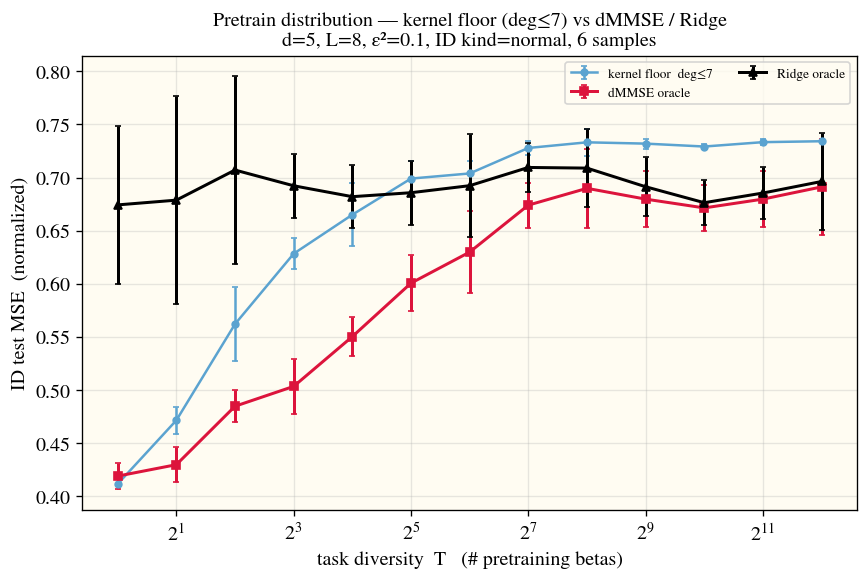

In [ ]:
plot_side(R_avg, 'id',  n_beta_samples, [max(CUTOFFS)],
    f"Pretrain distribution — kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind={KIND_TRAIN}, {n_beta_samples} samples")

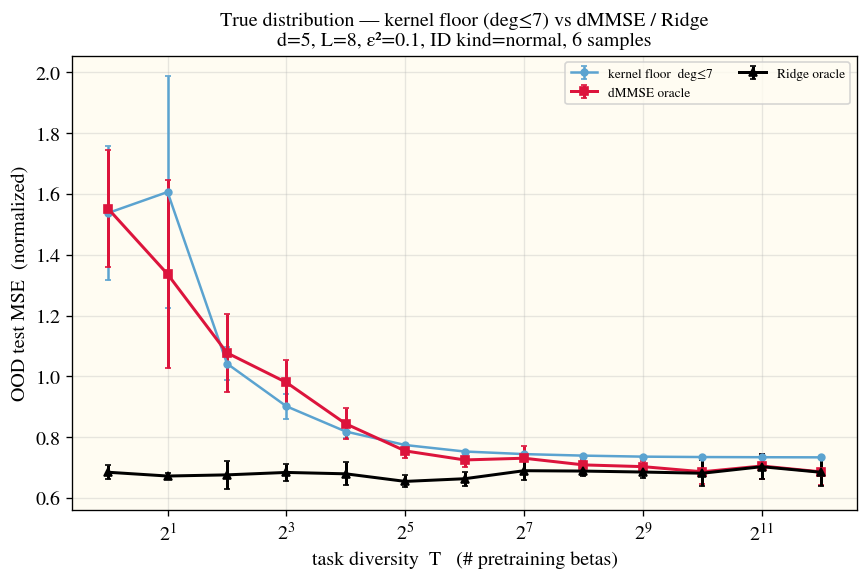

In [ ]:
plot_side(R_avg, 'ood', n_beta_samples, [max(CUTOFFS)],
    f"True distribution — kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind={KIND_TRAIN}, {n_beta_samples} samples")

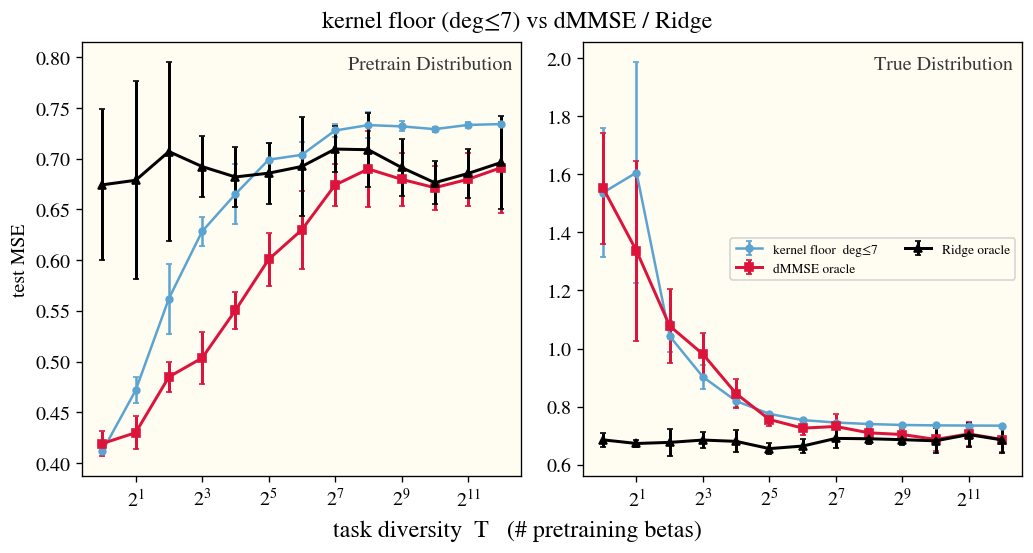

In [ ]:
# folder_path = '/content/drive/My Drive/picl/results/kernels/task_div_curve/'
# os.makedirs(folder_path, exist_ok=True)
fig, axes = plot_id_vs_ood(R_avg, n_beta_samples, [max(CUTOFFS)], f"kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge",
    figsize=(8.5, 4.5)) #d5, L8, epsilon^2=0.1
fig.savefig("/content/drive/My Drive/picl/results/kernels/task_div_curve/mse_deg7.pdf", dpi=130, bbox_inches="tight")

## Experiment 2 — kernel floor at every degree cutoff vs oracles

Same averaged data, now overlaying the kernel floor at cutoffs `{1,3,5,7}` (lower cutoff = coarser
model ≈ more regularization) with the two oracles.

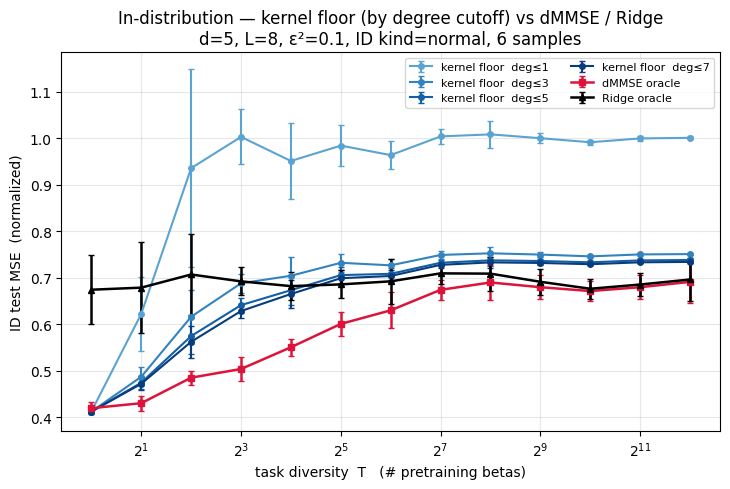

In [ ]:
plot_side(R_avg, 'id',  n_beta_samples, CUTOFFS,
    f"In-distribution — kernel floor (by degree cutoff) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind={KIND_TRAIN}, {n_beta_samples} samples")

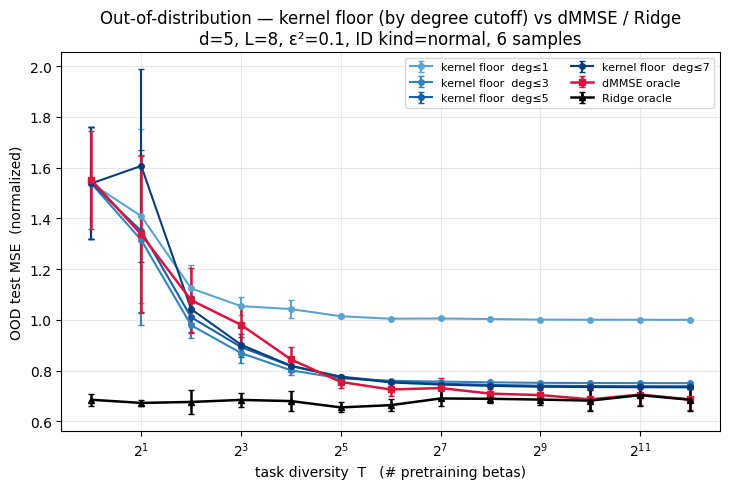

In [ ]:
plot_side(R_avg, 'ood', n_beta_samples, CUTOFFS,
    f"Out-of-distribution — kernel floor (by degree cutoff) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind={KIND_TRAIN}, {n_beta_samples} samples")

## Experiment 3 — single run (one `betas` per `T`, no averaging)

Same curves for one realization of the task set at each `T` (no error bars).

In [ ]:
R_one = run_sweep(T_list, 1, n_mc, seed + 1)

sweep: ID kind=normal, 1 sample(s)


  T=    1: floor(deg7) ID/OOD=0.412/1.130  dMMSE ID/OOD=0.447/1.067  (0.3s)


  T=    2: floor(deg7) ID/OOD=0.458/1.209  dMMSE ID/OOD=0.431/1.159  (0.2s)


  T=    4: floor(deg7) ID/OOD=0.606/1.089  dMMSE ID/OOD=0.461/1.166  (0.3s)


  T=    8: floor(deg7) ID/OOD=0.626/0.941  dMMSE ID/OOD=0.516/1.106  (0.3s)


  T=   16: floor(deg7) ID/OOD=0.680/0.832  dMMSE ID/OOD=0.518/0.813  (0.3s)


... (4 outputs left out)

  T=  512: floor(deg7) ID/OOD=0.722/0.737  dMMSE ID/OOD=0.634/0.694  (2.1s)


  T= 1024: floor(deg7) ID/OOD=0.733/0.735  dMMSE ID/OOD=0.747/0.708  (4.4s)


  T= 2048: floor(deg7) ID/OOD=0.734/0.735  dMMSE ID/OOD=0.678/0.661  (8.9s)


  T= 4096: floor(deg7) ID/OOD=0.738/0.734  dMMSE ID/OOD=0.730/0.679  (18.7s)
total 37.2s


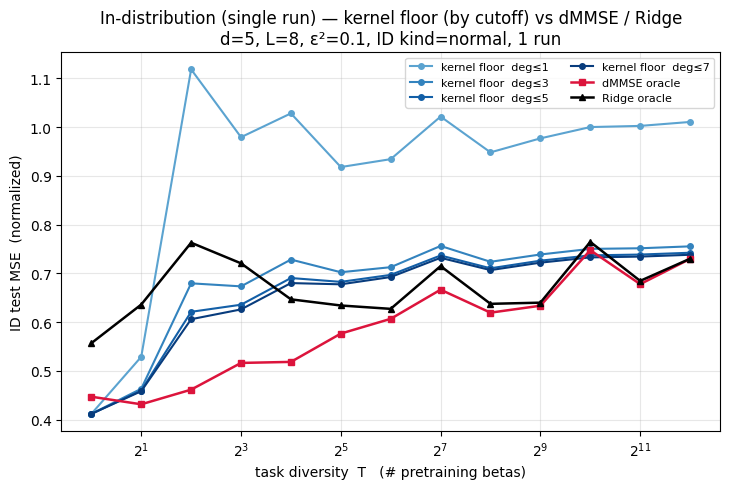

In [ ]:
plot_side(R_one, 'id',  1, CUTOFFS,
    f"In-distribution (single run) — kernel floor (by cutoff) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind={KIND_TRAIN}, 1 run")

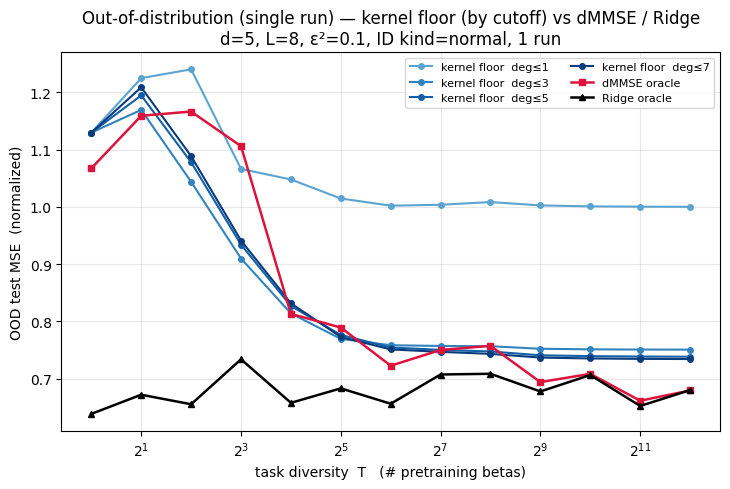

In [ ]:
plot_side(R_one, 'ood', 1, CUTOFFS,
    f"Out-of-distribution (single run) — kernel floor (by cutoff) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind={KIND_TRAIN}, 1 run")

## Experiment 4 — identical to Experiment 1, but ID kind = `ondiags`

Same deg-7 kernel floor vs dMMSE / Ridge, but the pretraining `betas` are drawn with
`kind="ondiags"` (zero mean, decorrelated so the empirical covariance is diagonal). Fresh averaged
sweep; the OOD test prior is still isotropic `N(0, I)` and everything is normalized by `norm2`.

In [ ]:
R_ondiags = run_sweep(T_list, n_beta_samples, n_mc, seed, kind="ondiags")

sweep: ID kind=ondiags, 6 sample(s)


  T=    1: floor(deg7) ID/OOD=0.412/1.000  dMMSE ID/OOD=0.419/1.027  (1.5s)


  T=    2: floor(deg7) ID/OOD=0.464/1.039  dMMSE ID/OOD=0.441/0.974  (1.5s)


  T=    4: floor(deg7) ID/OOD=0.550/0.957  dMMSE ID/OOD=0.474/1.021  (1.5s)


  T=    8: floor(deg7) ID/OOD=0.621/0.871  dMMSE ID/OOD=0.496/0.961  (1.6s)


  T=   16: floor(deg7) ID/OOD=0.661/0.802  dMMSE ID/OOD=0.562/0.844  (1.6s)


... (4 outputs left out)

  T=  512: floor(deg7) ID/OOD=0.732/0.736  dMMSE ID/OOD=0.680/0.699  (12.5s)


  T= 1024: floor(deg7) ID/OOD=0.729/0.735  dMMSE ID/OOD=0.685/0.692  (26.6s)


  T= 2048: floor(deg7) ID/OOD=0.733/0.734  dMMSE ID/OOD=0.682/0.709  (68.7s)


  T= 4096: floor(deg7) ID/OOD=0.734/0.734  dMMSE ID/OOD=0.691/0.687  (112.1s)
total 237.7s


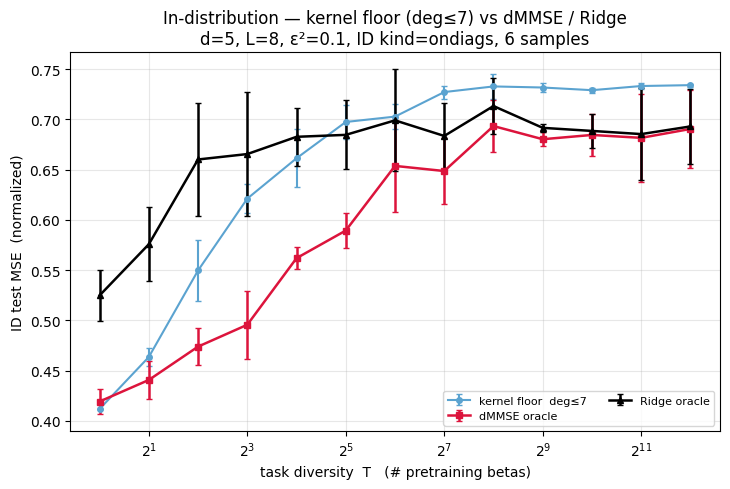

In [ ]:
plot_side(R_ondiags, 'id',  n_beta_samples, [max(CUTOFFS)],
    f"In-distribution — kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind=ondiags, {n_beta_samples} samples")

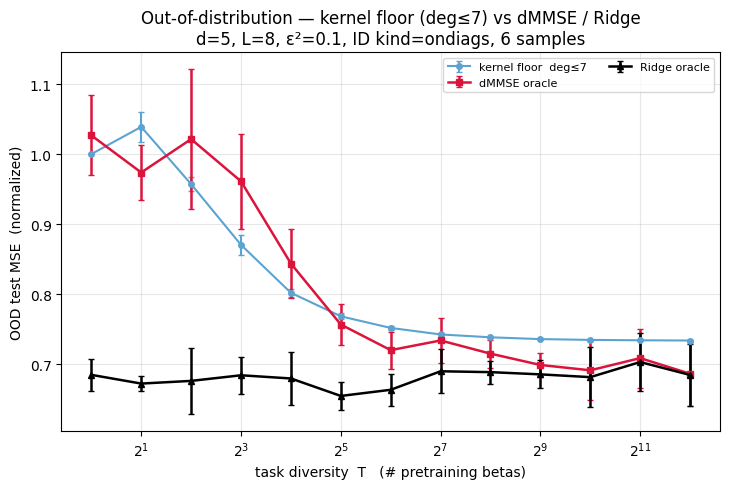

In [ ]:
plot_side(R_ondiags, 'ood', n_beta_samples, [max(CUTOFFS)],
    f"Out-of-distribution — kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind=ondiags, {n_beta_samples} samples")

## Experiment 5 — identical to Experiments 1 & 4, but ID kind = `isogauss`

Same deg-7 kernel floor vs dMMSE / Ridge, with pretraining `betas` drawn `kind="isogauss"` (covariance
forced to `I` *exactly*, higher moments isotropic + small). This **isotropizes** the task covariance
(not just diagonalizes it), aligning it with the isotropic OOD prior — so unlike `ondiags`, it actually
lowers the OOD floor at small T. Needs `T>d`, so `T≤5` are skipped.

In [ ]:
R_isogauss = run_sweep(T_list, n_beta_samples, n_mc, seed, kind="isogauss")

sweep: ID kind=isogauss, 6 sample(s)
  make_tasks('isogauss') skipped T=1: isogauss needs T > d for full-rank whitening.
  T=    1: floor(deg7) ID/OOD=nan/nan  dMMSE ID/OOD=nan/nan  (0.0s)
  make_tasks('isogauss') skipped T=2: isogauss needs T > d for full-rank whitening.
  T=    2: floor(deg7) ID/OOD=nan/nan  dMMSE ID/OOD=nan/nan  (0.0s)
  make_tasks('isogauss') skipped T=4: isogauss needs T > d for full-rank whitening.
  T=    4: floor(deg7) ID/OOD=nan/nan  dMMSE ID/OOD=nan/nan  (0.0s)
  T=    8: floor(deg7) ID/OOD=0.678/0.831  dMMSE ID/OOD=0.518/0.904  (14.3s)
  T=   16: floor(deg7) ID/OOD=0.697/0.785  dMMSE ID/OOD=0.579/0.820  (13.1s)
  T=   32: floor(deg7) ID/OOD=0.713/0.758  dMMSE ID/OOD=0.587/0.827  (24.7s)
  T=   64: floor(deg7) ID/OOD=0.724/0.745  dMMSE ID/OOD=0.624/0.745  (101.8s)
  T=  128: floor(deg7) ID/OOD=0.729/0.739  dMMSE ID/OOD=0.673/0.728  (19.7s)
  T=  256: floor(deg7) ID/OOD=0.731/0.736  dMMSE ID/OOD=0.690/0.694  (27.8s)
  T=  512: floor(deg7) ID/OOD=0.732/0.735  d

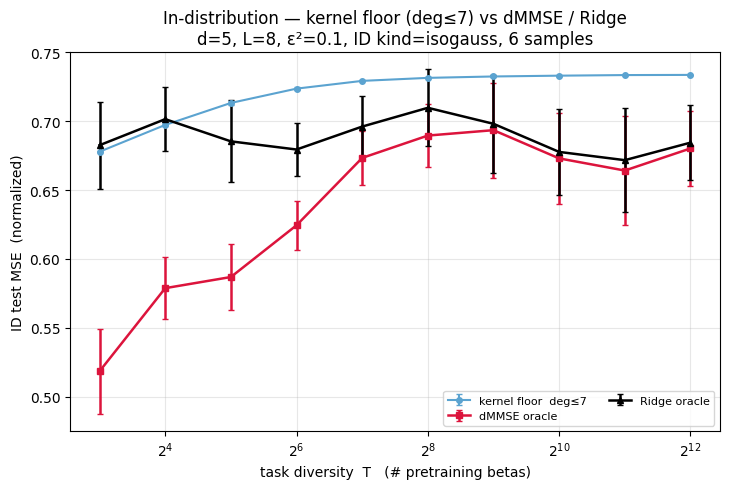

In [ ]:
plot_side(R_isogauss, 'id',  n_beta_samples, [max(CUTOFFS)],
    f"In-distribution — kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind=isogauss, {n_beta_samples} samples")

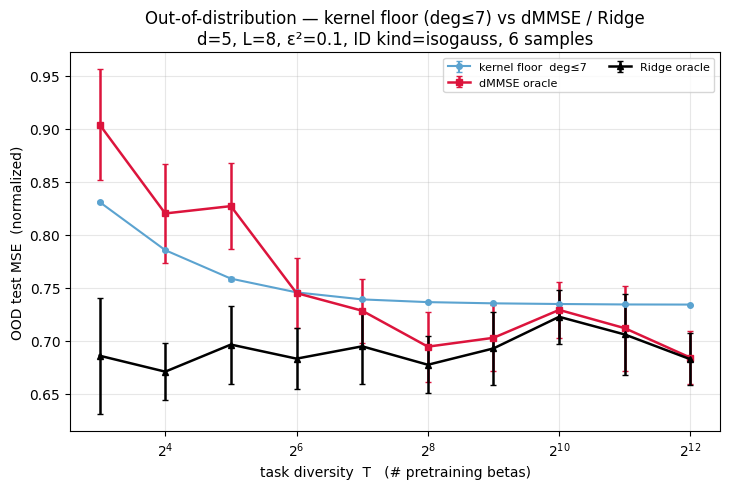

In [ ]:
plot_side(R_isogauss, 'ood', n_beta_samples, [max(CUTOFFS)],
    f"Out-of-distribution — kernel floor (deg≤{max(CUTOFFS)}) vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind=isogauss, {n_beta_samples} samples")

## Experiment 6 — off-diagonal suppression (bridging full ↔ per-axis)

Identical to Experiment 1 (deg-7 kernel, ID kind=`normal`), but overlaying several kernel curves where
the **off-diagonal / cross-axis features are suppressed by a factor** `λ`. The fitted eigcoefficients are
interpolated `w(λ) = w_axis + λ·(w_full − w_axis)`, so **λ=1** is the full anisotropic fit (= Exp 1) and
**λ=0** is the per-axis / rotation-covariant fit (diagonal features only). The off-diagonal features fit
the finite-T sampling anisotropy of the task set; suppressing them pulls the OOD floor toward Ridge at
small T and has ~no effect as T→∞ (the empirical covariance → I). (A "diagonal" feature has every context
coordinate equal to the query axis.)

In [ ]:
LAMS = [1.0, 0.5, 0.25, 0.0]         # off-diag suppression: 1=full (Exp 1), 0=per-axis / rotation-covariant
_pre7 = pre_by_deg[max(CUTOFFS)]

def _diag_mask(pre):
    """Reference-block features whose context coordinates all equal the query axis."""
    b0 = pre['b0']; blk0 = pre['blocks'][b0]; P = blk0['P']
    labs = [None]*P
    for lab, t in blk0['pos'].items(): labs[t] = lab
    m = np.zeros(P, bool)
    for t in range(P):
        _, inp, b = _feat_coords(labs[t]); m[t] = all(c == b for c in inp)
    return m
DMASK = _diag_mask(_pre7)
print(f"deg-{max(CUTOFFS)} reference block: {int(DMASK.sum())} diagonal / {int((~DMASK).sum())} off-diagonal features")

def ood_floors_suppress(pre, betas, sb2, lams, dmask):
    """ID/OOD floor as the OOD/ID risk of the train-fit predictor w(lam)=w_axis+lam*(w_full-w_axis),
    where w_full = Gp^-1 Vp (all features) and w_axis fits only the diagonal features. lam=1 reproduces
    ood_floors_fast; lam=0 is the per-axis / rotation-covariant solution."""
    betas = np.asarray(betas, float); T = betas.shape[0]
    d, vv, e, tol = pre['d'], pre['v'], pre['e'], pre['tol']
    b0 = pre['b0']; blk0 = pre['blocks'][b0]; Kmat = blk0['Kmat']; P = blk0['P']; di = np.where(dmask)[0]
    maxp = int(Kmat.max())+1 if Kmat.size else 1
    bp = betas[:, :, None] ** np.arange(maxp)[None, None, :]
    Gq, Vq = _assemble(blk0, _gauss_moments(Kmat, sb2), vv)             # gauss (isotropic) -> once
    signal_q = sb2*d*vv; signal_p = float(np.mean(np.sum(betas**2, 1)))*vv; norm2 = signal_q + e
    idc = {Lm: 0.0 for Lm in lams}; oodc = {Lm: 0.0 for Lm in lams}
    for b in pre['axes']:
        swap = list(range(d)); swap[b0], swap[b] = b, b0
        acc = np.ones((T, Kmat.shape[0]))
        for c in range(d): acc *= bp[:, swap[c], Kmat[:, c]]
        Gp, Vp = _assemble(blk0, acc.mean(0), vv)
        Gpr = Gp + tol*np.mean(np.diag(Gp))*np.eye(P)
        w_full = np.linalg.solve(Gpr, Vp)
        w_axis = np.zeros(P); w_axis[di] = np.linalg.solve(Gpr[np.ix_(di, di)], Vp[di])
        for Lm in lams:
            w = w_axis + Lm*(w_full - w_axis)
            oodc[Lm] += -2*(w @ Vq) + w @ Gq @ w
            idc[Lm]  += -2*(w @ Vp) + w @ Gp @ w
    return {Lm: (max((signal_p+e+idc[Lm])/norm2, 0.0), max((signal_q+e+oodc[Lm])/norm2, 0.0)) for Lm in lams}

def run_sweep_suppress(T_list, n_samples, n_mc, seed, lams):
    R = dict(id={Lm: np.full((n_samples, len(T_list)), np.nan) for Lm in lams},
             ood={Lm: np.full((n_samples, len(T_list)), np.nan) for Lm in lams})
    for k in ['dmmse_id', 'dmmse_ood', 'ridge_id', 'ridge_ood']:
        R[k] = np.full((n_samples, len(T_list)), np.nan)
    torch.manual_seed(seed); rng = np.random.default_rng(seed); t0 = time.time()
    for ti, T in enumerate(T_list):
        tt = time.time()
        for s in range(n_samples):
            betas = draw_betas(T, 'normal')
            fl = ood_floors_suppress(_pre7, betas, sigma_beta2, lams, DMASK)
            for Lm in lams:
                R['id'][Lm][s, ti] = fl[Lm][0]; R['ood'][Lm][s, ti] = fl[Lm][1]
            om = oracle_mse_one_betas(betas, dim, L_cfg, v, sigma_sq, sigma_beta, norm2, n_mc, rng)
            for k in ('dmmse_id', 'dmmse_ood', 'ridge_id', 'ridge_ood'):
                R[k][s, ti] = om[k]
        print(f"  T={T:5d}: OOD lam1/lam0={np.nanmean(R['ood'][max(lams)][:,ti]):.3f}/{np.nanmean(R['ood'][min(lams)][:,ti]):.3f}"
              f"  dMMSE/Ridge={np.nanmean(R['dmmse_ood'][:,ti]):.3f}/{np.nanmean(R['ridge_ood'][:,ti]):.3f}  ({time.time()-tt:.1f}s)")
    print(f"total {time.time()-t0:.1f}s")
    return R

def plot_suppress(R, side, n_samples, lams, title):
    plt.figure(figsize=(7.6, 5.0))
    order = sorted(lams, reverse=True)
    cols = plt.cm.viridis(np.linspace(0.12, 0.88, len(order)))
    for ci, Lm in enumerate(order):
        m = np.nanmean(R[side][Lm], 0); sd = np.nanstd(R[side][Lm], 0)
        tag = " (full)" if Lm == 1 else (" (per-axis)" if Lm == 0 else "")
        lab = f"kernel  off-diag×{Lm:g}{tag}"
        if n_samples > 1:
            plt.errorbar(T_list, m, yerr=sd, marker='o', ms=4, lw=1.5, color=cols[ci], capsize=2, label=lab)
        else:
            plt.plot(T_list, m, marker='o', ms=4, lw=1.5, color=cols[ci], label=lab)
    for k, lab, col, mk in [(f'dmmse_{side}', "dMMSE oracle", 'crimson', 's'),
                            (f'ridge_{side}', "Ridge oracle", 'black', '^')]:
        m = np.nanmean(R[k], 0); sd = np.nanstd(R[k], 0)
        if n_samples > 1:
            plt.errorbar(T_list, m, yerr=sd, marker=mk, ms=5, lw=1.8, color=col, capsize=2, label=lab)
        else:
            plt.plot(T_list, m, marker=mk, ms=5, lw=1.8, color=col, label=lab)
    plt.xscale('log', base=2); plt.xlabel("task diversity  T   (# pretraining betas)")
    plt.ylabel(f"{side.upper()} test MSE  (normalized)")
    plt.title(title); plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

deg-7 reference block: 14 diagonal / 130 off-diagonal features


In [ ]:
R_supp = run_sweep_suppress(T_list, n_beta_samples, n_mc, seed, LAMS)

  T=    1: OOD lam1/lam0=1.538/1.538  dMMSE/Ridge=1.552/0.685  (0.2s)
  T=    2: OOD lam1/lam0=1.607/1.182  dMMSE/Ridge=1.337/0.673  (0.2s)
  T=    4: OOD lam1/lam0=1.042/0.868  dMMSE/Ridge=1.078/0.676  (0.2s)
  T=    8: OOD lam1/lam0=0.902/0.818  dMMSE/Ridge=0.980/0.684  (0.2s)
  T=   16: OOD lam1/lam0=0.819/0.771  dMMSE/Ridge=0.844/0.680  (0.2s)
  T=   32: OOD lam1/lam0=0.775/0.753  dMMSE/Ridge=0.755/0.655  (0.3s)
  T=   64: OOD lam1/lam0=0.753/0.743  dMMSE/Ridge=0.726/0.664  (0.5s)
  T=  128: OOD lam1/lam0=0.745/0.742  dMMSE/Ridge=0.731/0.690  (0.9s)
  T=  256: OOD lam1/lam0=0.740/0.740  dMMSE/Ridge=0.709/0.689  (2.4s)
  T=  512: OOD lam1/lam0=0.736/0.738  dMMSE/Ridge=0.704/0.686  (9.9s)
  T= 1024: OOD lam1/lam0=0.735/0.738  dMMSE/Ridge=0.687/0.682  (22.8s)
  T= 2048: OOD lam1/lam0=0.735/0.738  dMMSE/Ridge=0.706/0.703  (53.8s)
  T= 4096: OOD lam1/lam0=0.734/0.737  dMMSE/Ridge=0.686/0.685  (270.5s)
total 362.0s


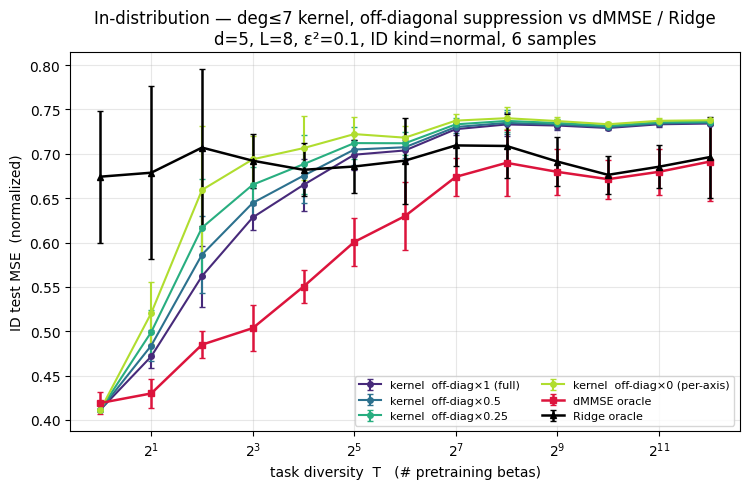

In [ ]:
plot_suppress(R_supp, 'id',  n_beta_samples, LAMS,
    f"In-distribution — deg≤{max(CUTOFFS)} kernel, off-diagonal suppression vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind=normal, {n_beta_samples} samples")

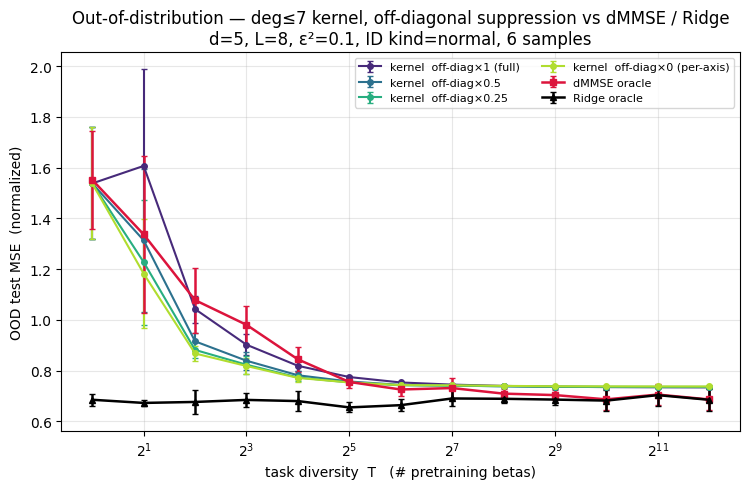

In [ ]:
plot_suppress(R_supp, 'ood', n_beta_samples, LAMS,
    f"Out-of-distribution — deg≤{max(CUTOFFS)} kernel, off-diagonal suppression vs dMMSE / Ridge\n"
    f"d={dim}, L={L_cfg}, ε²={sigma_sq}, ID kind=normal, {n_beta_samples} samples")

## Save results (optional)

In [ ]:
SAVE_PATH = os.path.join(os.getcwd(), "ood_floor_vs_taskdiversity_results.pkl")
def _pack(R):
    d = {k: R[k] for k in ['dmmse_id','dmmse_ood','ridge_id','ridge_ood']}
    d['floor_id']  = {deg: R['floor_id'][deg]  for deg in CUTOFFS}
    d['floor_ood'] = {deg: R['floor_ood'][deg] for deg in CUTOFFS}
    return d
savedict = dict(
    params=dict(dim=dim, L_cfg=L_cfg, sigma_sq=sigma_sq, sigma_beta2=sigma_beta2, v=v, norm2=norm2,
                KIND_TRAIN=KIND_TRAIN, CUTOFFS=CUTOFFS, n_beta_samples=n_beta_samples, n_mc=n_mc, seed=seed),
    T_list=np.array(T_list), averaged=_pack(R_avg), single=_pack(R_one), ondiags=_pack(R_ondiags),
)
with open(SAVE_PATH, "wb") as f:
    pickle.dump(savedict, f)
print("saved ->", SAVE_PATH)

saved -> C:\Users\joeyj\AppData\Local\Temp\claude\C--Users-joeyj\a4e9852b-0924-4df0-8b83-2225dd95d30a\scratchpad\ood_floor_vs_taskdiversity_results.pkl
